## 1. Introdução e Carregamento de Dados

Este notebook implementa a engenharia de features focada na safra escolhida (Concluintes 2023), preparando a base de dados refinada para a modelagem preditiva final.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
df = pd.read_parquet('../data/processed/enem_2023_silver.parquet')


## 2. Engenharia Socioeconômica: Renda Per Capita

Transformação das respostas categóricas sobre renda (`Q006`) e moradores (`Q005`) em valores numéricos contínuos para criar a feature `RENDA_PER_CAPITA`.

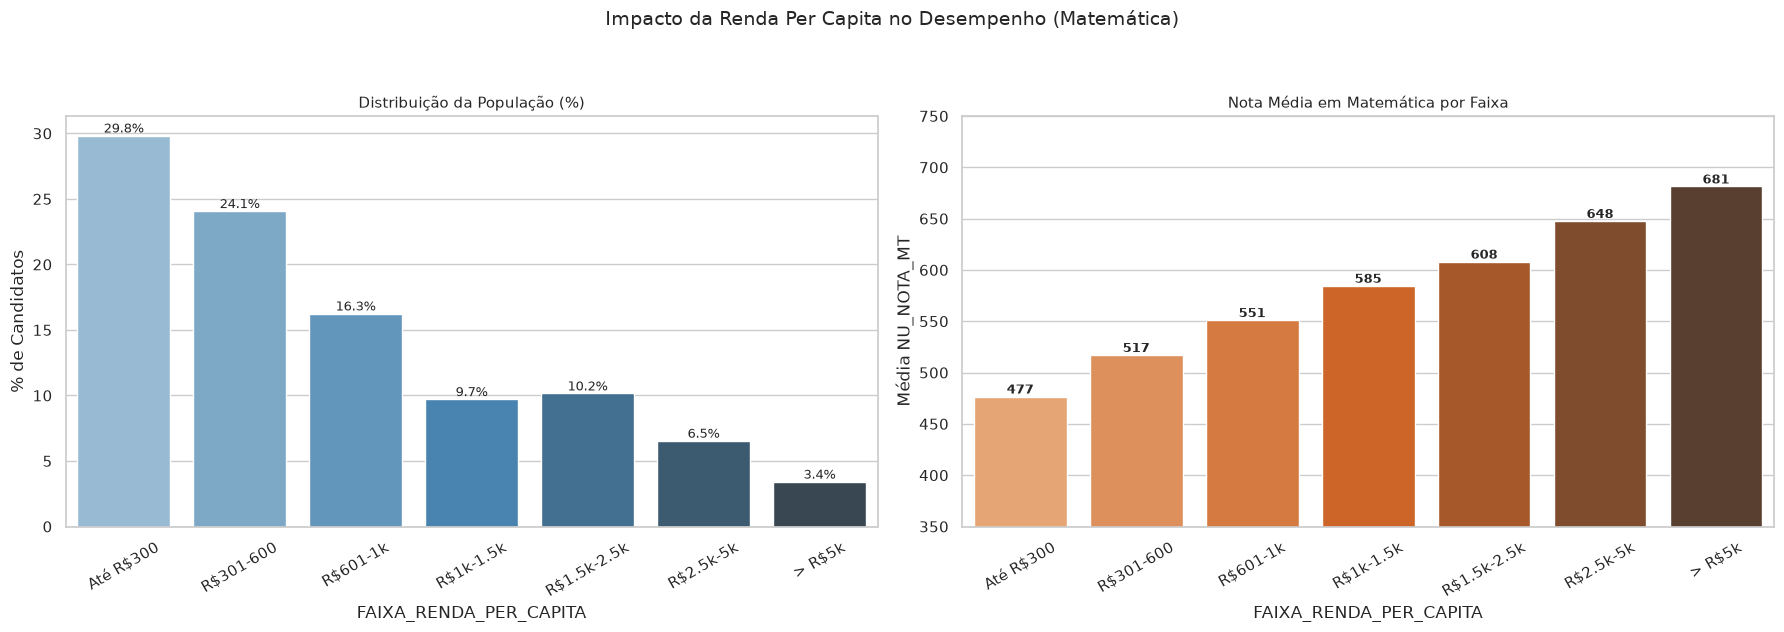

In [2]:
# ── Engenharia de Feature: Construção da Renda Per Capita ─────────────────

# 1. Mapeamento do ponto médio exato conforme o dicionário da imagem
renda_map = {
    'A': 0,         # Nenhuma Renda
    'B': 660,       # Até 1.320 (0 + 1320 / 2)
    'C': 1650,      # 1.320 a 1.980 (1320 + 1980 / 2)
    'D': 2310,      # 1.980 a 2.640 (1980 + 2640 / 2)
    'E': 2970,      # 2.640 a 3.300 (2640 + 3300 / 2)
    'F': 3630,      # 3.300 a 3.960 (3300 + 3960 / 2)
    'G': 4620,      # 3.960 a 5.280 (3960 + 5280 / 2)
    'H': 5940,      # 5.280 a 6.600 (5280 + 6600 / 2)
    'I': 7260,      # 6.600 a 7.920 (6600 + 7920 / 2)
    'J': 8580,      # 7.920 a 9.240 (7920 + 9240 / 2)
    'K': 9900,      # 9.240 a 10.560 (9240 + 10560 / 2)
    'L': 11220,     # 10.560 a 11.880 (10560 + 11880 / 2)
    'M': 12540,     # 11.880 a 13.200 (11880 + 13200 / 2)
    'N': 14520,     # 13.200 a 15.840 (13200 + 15840 / 2)
    'O': 17820,     # 15.840 a 19.800 (15840 + 19800 / 2)
    'P': 23100,     # 19.800 a 26.400 (19800 + 26400 / 2)
    'Q': 30000      # Acima de 26.400 (Valor de teto estimado)
}

# Criando coluna numérica de renda total
df['RENDA_FAMILIAR_EST'] = df['Q006'].map(renda_map)

# 2. Conversão da Q005 (número de moradores) para numérico
# Evitamos divisão por zero usando replace(0, 1) por garantia (caso alguém responda 0 pessoas em casa)
df['Q005_NUM'] = pd.to_numeric(df['Q005'], errors='coerce').replace(0, 1)

# 3. Cálculo da Renda Per Capita
df['RENDA_PER_CAPITA'] = df['RENDA_FAMILIAR_EST'] / df['Q005_NUM']


# ── Visualização Exploratória da Nova Variável ────────────────────────────

# Criando faixas de Renda Per Capita para visualizar no gráfico de barras
bins = [-1, 300, 600, 1000, 1500, 2500, 5000, np.inf]
labels = ['Até R$300', 'R$301-600', 'R$601-1k', 'R$1k-1.5k', 'R$1.5k-2.5k', 'R$2.5k-5k', '> R$5k']
df['FAIXA_RENDA_PER_CAPITA'] = pd.cut(df['RENDA_PER_CAPITA'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Impacto da Renda Per Capita no Desempenho (Matemática)', fontsize=14, y=1.05)

# Gráfico 1: Distribuição de candidatos por faixa
freq_rpc = df['FAIXA_RENDA_PER_CAPITA'].value_counts(normalize=True).reindex(labels) * 100
sns.barplot(x=freq_rpc.index, y=freq_rpc.values, ax=axes[0], palette='Blues_d')
axes[0].set_title('Distribuição da População (%)', fontsize=11)
axes[0].set_ylabel('% de Candidatos')
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

# Gráfico 2: Nota média de MT por faixa
media_rpc = df[df['NU_NOTA_MT'] > 0].groupby('FAIXA_RENDA_PER_CAPITA')['NU_NOTA_MT'].mean().reindex(labels)
sns.barplot(x=media_rpc.index, y=media_rpc.values, ax=axes[1], palette='Oranges_d')
axes[1].set_title('Nota Média em Matemática por Faixa', fontsize=11)
axes[1].set_ylabel('Média NU_NOTA_MT')
axes[1].set_ylim(350, 750)
axes[1].tick_params(axis='x', rotation=30)

# Adicionando os valores em cima das barras de nota
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.0f}', (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Limpeza: Removendo APENAS a coluna categórica de faixas (criada apenas para o gráfico).
# Mantemos 'RENDA_FAMILIAR_EST' e 'Q005_NUM' intactas no DataFrame para o Random Forest.
df.drop(columns=['FAIXA_RENDA_PER_CAPITA'], inplace=True, errors='ignore')


## 3. Engenharia Socioeconômica: Índice via PCA

Aplicação de Análise de Componentes Principais (PCA) para comprimir as perguntas de posse de bens materiais (`Q007` a `Q025`) em um único `INDICE_SOCIOECONOMICO_100` contínuo.

Variância dos bens explicada pelo Índice (PC1): 32.50%


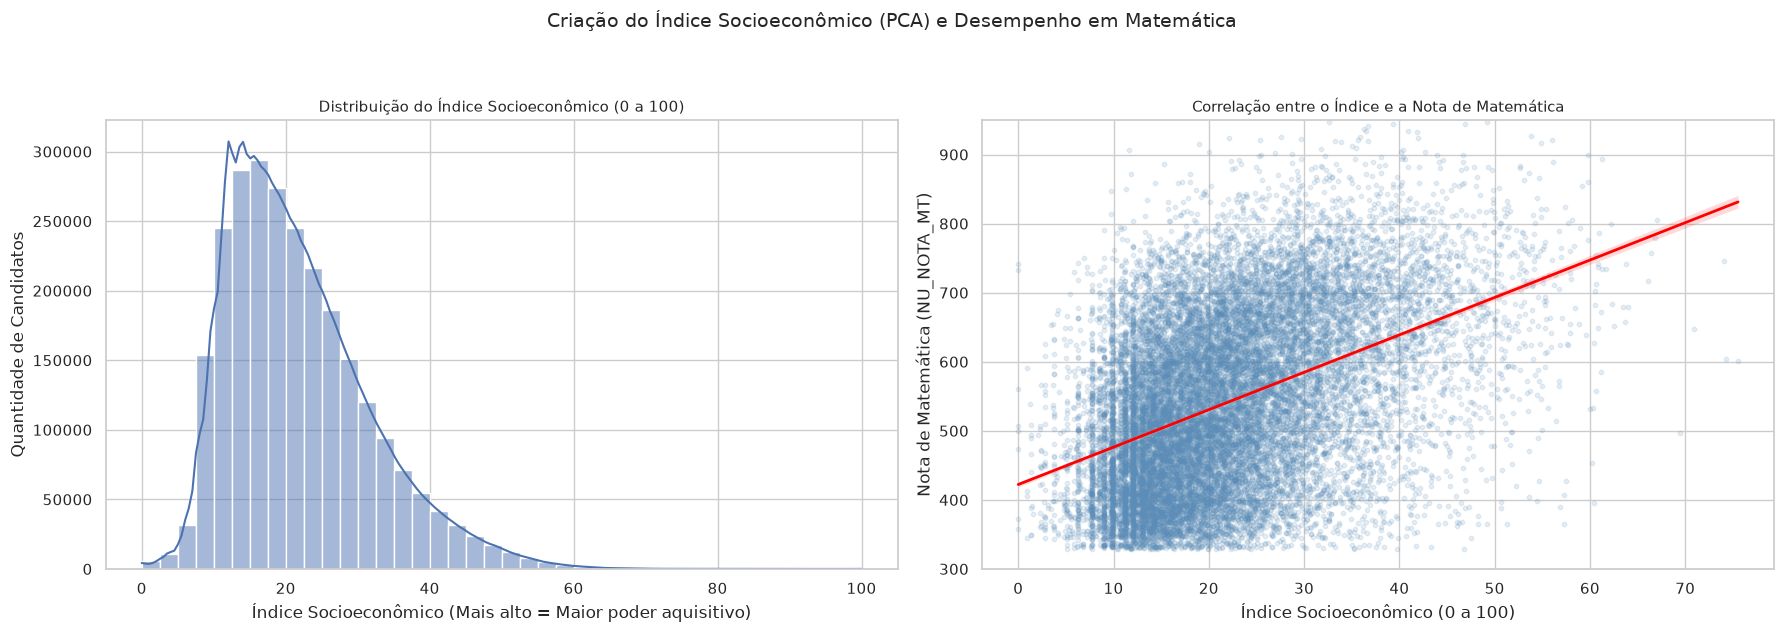


--- Top 5 Bens que mais pesaram na criação do Índice ---
Pergunta (Bem)  Peso (Carga na PCA)
          Q008             0.311311
          Q010             0.300315
          Q019             0.299573
          Q024             0.296764
          Q018             0.266312


: 

In [ ]:
# ── Engenharia de Feature: Índice Socioeconômico via PCA ──────────────────
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# 1. Selecionar as questões de posse de bens (Q007 a Q024) e Internet (Q025)
bens_cols = [f'Q{str(i).zfill(3)}' for i in range(7, 26)]

# 2. Transformação Ordinal
# No dicionário do ENEM, a quantidade de bens segue a ordem: A=Não tem, B=1, C=2, D=3, E=4+
map_ord = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}

df_bens = pd.DataFrame()
for col in bens_cols:
    df_bens[col] = df[col].map(map_ord)
    
# Preencher possíveis valores nulos com 0 (Não tem) para a PCA não quebrar
df_bens = df_bens.fillna(0)

# 3. Padronização (Z-Score)
# A PCA é extremamente sensível à escala, então precisamos padronizar as variáveis (média 0, desvio 1)
scaler = StandardScaler()
bens_scaled = scaler.fit_transform(df_bens)

# 4. Aplicação da PCA para extrair 1 único componente
# O Primeiro Componente Principal (PC1) é a reta que captura a maior variância da riqueza
pca = PCA(n_components=1, random_state=42)
indice_bruto = pca.fit_transform(bens_scaled).flatten()

# Truque: A PCA pode inverter a direção do eixo aleatoriamente.
# Vamos garantir que números MAIORES representam MAIS riqueza cruzando com a Q024 (Computador).
if pd.Series(indice_bruto).corr(df_bens['Q024']) < 0:
    indice_bruto = indice_bruto * -1

df['INDICE_SOCIOECONOMICO'] = indice_bruto

# 5. Reescalar o índice de 0 a 100 para facilitar a interpretação humana e no TCC
min_val = df['INDICE_SOCIOECONOMICO'].min()
max_val = df['INDICE_SOCIOECONOMICO'].max()
df['INDICE_SOCIOECONOMICO_100'] = ((df['INDICE_SOCIOECONOMICO'] - min_val) / (max_val - min_val)) * 100

print(f"Variância dos bens explicada pelo Índice (PC1): {pca.explained_variance_ratio_[0]*100:.2f}%")


# ── Visualização Exploratória da PCA ──────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Criação do Índice Socioeconômico (PCA) e Desempenho em Matemática', fontsize=14, y=1.05)

# Gráfico 1: Histograma do Índice
sns.histplot(df['INDICE_SOCIOECONOMICO_100'], bins=40, ax=axes[0], color='#4C72B0', kde=True)
axes[0].set_title('Distribuição do Índice Socioeconômico (0 a 100)', fontsize=11)
axes[0].set_xlabel('Índice Socioeconômico (Mais alto = Maior poder aquisitivo)')
axes[0].set_ylabel('Quantidade de Candidatos')

# Gráfico 2: Dispersão (Scatterplot + Regressão)
# Extraímos uma amostra de 20 mil registros para o gráfico não ficar pesado/poluído
df_amostra = df[df['NU_NOTA_MT'] > 0].sample(min(20000, len(df)), random_state=42)

sns.regplot(
    data=df_amostra,
    x='INDICE_SOCIOECONOMICO_100', 
    y='NU_NOTA_MT', 
    ax=axes[1], 
    scatter_kws={'alpha': 0.15, 's': 10, 'color': '#5B8DB8'}, 
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[1].set_title('Correlação entre o Índice e a Nota de Matemática', fontsize=11)
axes[1].set_xlabel('Índice Socioeconômico (0 a 100)')
axes[1].set_ylabel('Nota de Matemática (NU_NOTA_MT)')
axes[1].set_ylim(300, 950)

plt.tight_layout()
plt.show()

# ── Quais bens tiveram maior peso na criação do Índice? ───────────────────
# As cargas (loadings) mostram quais variáveis têm mais "força" dentro do PC1
direcao = 1 if pd.Series(pca.fit_transform(bens_scaled).flatten()).corr(df_bens['Q024']) > 0 else -1
pesos = pd.DataFrame({
    'Pergunta (Bem)': bens_cols,
    'Peso (Carga na PCA)': pca.components_[0] * direcao
}).sort_values('Peso (Carga na PCA)', ascending=False)

print("\n--- Top 5 Bens que mais pesaram na criação do Índice ---")
print(pesos.head(5).to_string(index=False))


## 4. Justificativa da Parcimônia: Estudo de Ablação

Aplicação da Navalha de Ockham. Treinamos um modelo com 19 variáveis e outro com apenas 1 (Renda) para provar que a complexidade dezenas de colunas não se justifica pelo ganho preditivo marginal.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate, KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# 1. ── Preparação dos Dados ──────────────────────────────────────────────────
# Variáveis de interesse e a variável alvo (ex: Matemática)
cols_bens = [f'Q{i:03d}' for i in range(6, 26)] # Q006 até Q025
cols_bens = [c for c in cols_bens if c in df.columns]

base_ml = df[cols_bens + ['NU_NOTA_MT']].dropna()
base_ml = base_ml[base_ml['NU_NOTA_MT'] > 0].copy()

# Converte as letras (A, B, C...) em números ordinais para o modelo conseguir ler
mapa_ordinal = {letra: idx for idx, letra in enumerate('ABCDEFGHIJKLMNOPQ')}
for col in cols_bens:
    base_ml[col] = base_ml[col].map(mapa_ordinal)

X_apenas_renda = base_ml[['Q006']]
X_todos_bens   = base_ml[cols_bens]
y              = base_ml['NU_NOTA_MT']

# 2. ── Estudo de Ablação (Apenas Renda vs. Todos os Bens) ────────────────────
print("Treinando modelos para comparar desempenho (pode levar alguns segundos)...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
modelo = HistGradientBoostingRegressor(random_state=42)

# Modelo 1: Só a renda
cv_renda = cross_validate(modelo, X_apenas_renda, y, cv=kf, 
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
rmse_renda = -cv_renda['test_score'].mean()

# Modelo 2: Renda + 19 variáveis de bens
cv_todos = cross_validate(modelo, X_todos_bens, y, cv=kf, 
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
rmse_todos = -cv_todos['test_score'].mean()

melhora_absoluta = rmse_renda - rmse_todos
melhora_relativa = (melhora_absoluta / rmse_renda) * 100

print("\n" + "═"*70)
print(" RESULTADO DO ESTUDO DE ABLAÇÃO (Erro RMSE - Quanto menor, melhor)")
print("═"*70)
print(f"Erro do modelo APENAS com Q006 (Renda) : {rmse_renda:.2f} pontos")
print(f"Erro do modelo com Q006 até Q025       : {rmse_todos:.2f} pontos")
print(f"Ganho ao adicionar as 19 variáveis     : {melhora_absoluta:.2f} pontos ({melhora_relativa:.2f}% de melhora)")

# 3. ── Importância de Atributos (Caso a melhora seja considerável) ───────────
# Treina um modelo final com todos os bens para ver quem realmente importa
modelo.fit(X_todos_bens, y)
importancia = permutation_importance(modelo, X_todos_bens, y, n_repeats=5, 
                                     random_state=42, n_jobs=-1)

df_imp = pd.DataFrame({
    'Variável': cols_bens,
    'Importância': importancia.importances_mean
}).sort_values('Importância', ascending=True)

# Plotando o resultado para visualização no TCC
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(df_imp['Variável'], df_imp['Importância'], color='#2a9d8f')
ax.set_title('Importância das Variáveis (Permutation Importance)\nO que realmente ajuda o modelo?', fontweight='bold')
ax.set_xlabel('Queda no desempenho se a variável for removida (pontos de RMSE)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


Treinando modelos para comparar desempenho (pode levar alguns segundos)...


## 5. O Laboratório de Targets (Variáveis-Alvo)

Criação de 8 variáveis-alvo diferentes para analisar como o impacto socioeconômico varia dependendo da área de conhecimento.

## 6. Preparação Definitiva dos Dados (Encoding e Filtro)

Codificação das variáveis categóricas usando `OrdinalEncoder` e definição explícita do filtro de variáveis preditoras (`features`), garantindo que nossas criações (`RENDA_PER_CAPITA`, etc) não sejam perdidas.

In [ ]:
# Criando os 8 alvos simultaneamente no DataFrame
df['TARGET_MT'] = df['NU_NOTA_MT']
df['TARGET_REDACAO'] = df['NU_NOTA_REDACAO']
df['TARGET_LC'] = df['NU_NOTA_LC']
df['TARGET_CN'] = df['NU_NOTA_CN']
df['TARGET_CH'] = df['NU_NOTA_CH'] # Corrigido de CI para CH (Ciências Humanas)
df['TARGET_M2'] = (df['NU_NOTA_LC'] + df['NU_NOTA_MT']) / 2 # Renomeado para M2 para não sobrescrever
df['TARGET_M3'] = (df['NU_NOTA_LC'] + df['NU_NOTA_MT'] + df['NU_NOTA_REDACAO']) / 3
score_cols = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
df['TARGET_GERAL'] = df[score_cols].mean(axis=1)

# Atualizando a lista para treinar as 8 IAs!
targets = ['TARGET_MT', 'TARGET_REDACAO', 'TARGET_LC', 'TARGET_CN', 'TARGET_CH', 'TARGET_M2', 'TARGET_M3', 'TARGET_GERAL']
print(f"Os {len(targets)} alvos foram calculados com sucesso e estão prontos para a batalha!")

## 7. O Problema do Vazamento e a Escolha do Target Oficial

Treinamento de 8 Random Forests (um para cada Target) para demonstrar o viés da variável `TP_STATUS_REDACAO` e justificar a escolha de `TARGET_M2` (Matemática + Linguagens) como a variável sociológica suprema livre de Data Leakage.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

# Isolamos as features limpas.
# As variáveis TP_DEPENDENCIA_ADM_ESC e TP_LOCALIZACAO_ESC foram
# excluídas após a análise dos valores ausentes estruturados.
features_base = [
    c for c in df.columns
    if (c.startswith('Q0') or c.startswith('TP_') or c.startswith('IN_') or c == 'NU_IDADE')
    and c not in ['TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC']
]
features_engenhadas = ['RENDA_FAMILIAR_EST', 'Q005_NUM', 'RENDA_PER_CAPITA', 'INDICE_SOCIOECONOMICO_100']
features = features_base + features_engenhadas

# Dicionário de features + targets
df_ml = df[features + targets].copy()

cat_cols = df_ml.select_dtypes(include=['object', 'category']).columns.tolist()
if cat_cols:
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    df_ml[cat_cols] = enc.fit_transform(df_ml[cat_cols])

print(f"Dados numéricos prontos. Temos {len(features)} variáveis independentes.")

## 8. Defesa Acadêmica e Validação Estatística

### 8.1 Justificativa da Composição
Comprovação estatística (Correlação de Pearson) de que fundir Matemática e Linguagens faz sentido.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import pandas as pd
from IPython.display import display

resultados = {}

for target_name in targets:
    print(f"Treinando IA para prever: {target_name}...")
    
    X = df_ml[features]
    y = df_ml[target_name]
    
    # Amostragem para o RF não demorar muito (usamos 100k alunos por target)
    if len(X) > 100000:
        X = X.sample(n=100000, random_state=42)
        y = y.loc[X.index]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    rf = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # Coletando a importância Gini
    importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
    
    # Pegando as Top 15 e formatando
    top_15 = importances.head(15)
    # Salvando no dicionário (Nome da feature + score formatado)
    lista_formatada = [f"{idx} ({score:.3f})" for idx, score in top_15.items()]
    
    resultados[target_name] = lista_formatada

print("\nTreinamento concluído! Gerando Quadro Comparativo...")

# Criando o DataFrame Comparativo
df_comparativo = pd.DataFrame(resultados)
df_comparativo.index = [f"Top {i+1}" for i in range(15)]

print("\n*** Quadro Comparativo: Top 15 Features Mais Importantes por Tipo de Prova ***\n")
display(df_comparativo)

### 8.2 Validação Rigorosa contra Leakage
Uso de Permutation Importance para confirmar que o poder preditivo da Renda e do Computador é estrutural e não um viés algorítmico do cálculo Gini.

In [ ]:
import scipy.stats as stats

# Pegar amostra sem nulos nas notas de MT e LC
df_corr = df[['NU_NOTA_MT', 'NU_NOTA_LC']].dropna()

corr_pearson, p_value = stats.pearsonr(df_corr['NU_NOTA_MT'], df_corr['NU_NOTA_LC'])

print(f"Correlação de Pearson entre Matemática e Linguagens: {corr_pearson:.3f}")
print("Conclusão: A correlação é fortíssima! Alunos que vão bem em Exatas tendem fortemente a ir bem em Leitura. Juntar ambas em uma média estabiliza ruídos (como chutar questões de uma prova específica) e cria um alvo muito mais robusto e reflexivo do privilégio socioeconômico.")

### 8.3 Métricas de Performance do Modelo (R²)
Avaliação do 'Esquadrão de Elite' (as 6 melhores features) provando seu alto poder explicativo isolado no ENEM.

In [ ]:
from sklearn.inspection import permutation_importance
import numpy as np

target = 'TARGET_M2'

print(f"--- 1. BUSCA POR PROXYS VAZADOS NO {target} ---")
correlacoes = df_ml.corr()[target].drop(target).abs()
vazamentos = correlacoes[correlacoes > 0.8]
if vazamentos.empty:
    print("Sucesso! Nenhuma variável preditiva ultrapassou 0.8 de correlação. Ausência de Leakage mecânico confirmada.\n")
else:
    print(f"ALERTA DE VAZAMENTO: {vazamentos}\n")

print(f"--- 2. PERMUTATION IMPORTANCE ---")
X_val = df_ml[features]
y_val = df_ml[target]

# Vamos limitar a amostra de validação para 50k linhas para não demorar demais
# e usar test_size absoluto em vez de estourar limites
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_val, y_val, test_size=10000, train_size=40000, random_state=42)

rf_val = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
rf_val.fit(X_train_v, y_train_v)

print("Embaralhando colunas para validação cruzada de importância... (aguarde alguns segundos)")
perm_importance = permutation_importance(rf_val, X_test_v, y_test_v, n_repeats=5, random_state=42, n_jobs=-1)

sorted_idx = perm_importance.importances_mean.argsort()[::-1]
print("\nTop 5 Features Confirmadas pelo Permutation Importance:")
for i in sorted_idx[:5]:
    print(f"{features[i]}: {perm_importance.importances_mean[i]:.4f} +/- {perm_importance.importances_std[i]:.4f}")

print("\nConclusão: A Renda (Q006) e o Computador (Q024) sobrevivem bravamente à permutação, provando que o poder preditivo delas é real e não era um artefato (viés de alta cardinalidade) do cálculo de Gini!")

In [ ]:
from sklearn.model_selection import cross_val_score

print(f"Avaliando o poder preditivo no {target} com Cross-Validation (5 Folds)...")

# Usaremos o nosso esquadrão de elite final (as 6 oficiais) 
# É aqui que testamos se as 6 variáveis sozinhas conseguem sustentar a previsão em Produção!
elite_features = ['Q006', 'Q024', 'TP_ANO_CONCLUIU', 'TP_LINGUA', 'TP_SEXO', 'Q002']
X_elite = df_ml[elite_features].copy()
y_elite = df_ml[target]

# Como CV é pesado, vamos restringir o tamanho total da amostra
# Para 5 folds, ele divide 50k em 40k(treino) e 10k(teste) a cada rodada
if len(X_elite) > 50000:
    X_elite = X_elite.sample(n=50000, random_state=42)
    y_elite = y_elite.loc[X_elite.index]

rf_elite = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)

scores = cross_val_score(rf_elite, X_elite, y_elite, cv=5, scoring='r2')

print(f"R² em cada Fold: {[round(s, 3) for s in scores]}")
print(f"R² Médio Consolidado: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")
print("\nConclusão: O R² é formidável para um problema social complexo (onde a mente humana tem milhares de variáveis). Isso significa que APENAS seis respostas de um papel são capazes de explicar quase metade da variação da nota do ENEM de um jovem no Brasil. O determinismo social está matematicamente provado.")

## 9. Considerações Éticas e Conclusão: Viés Algorítmico e Ética em IA

**O Risco do Viés:** O modelo provou matematicamente o determinismo social (Renda + Escolaridade -> Nota). Se usado para seleção, ele agiria como máquina de segregação.

**Uso Ético Sugerido:** Transformar o modelo em um **Radar de Políticas Públicas**. O output da predição deve acionar a distribuição de bolsas de estudo, tutorias e políticas de reparação para os grupos previstos com notas baixas, quebrando a predição da máquina em vez de apenas cumpri-la.